# 7. Hafta - Nihai Model Seçimi, Hata Analizi ve Modelin Kaydedilmesi
**Ders:** Bilgisayar Mühendisliği Tasarımı | **Ekip:** Konut Fiyatlandırıcı
**Ekip Üyeleri:** Kübra Tüten, Rua Melhem, Onur Fidan

Bu not defteri, 4. ve 5. haftada kurulan **252 sütunluk ön işleme hattını** kullanarak:
1. Ridge için ceza katsayısı (alpha) aramasını genişletir,
2. Gereksinimdeki düz **Linear Regression** modelini de karşılaştırmaya ekler (FR-07),
3. Dört modelin beş katlı çapraz doğrulama ve test sonuçlarını, **eğitim süreleriyle** birlikte verir (NFR-04),
4. Belirli bir kurala göre **nihai modeli seçer** (FR-11),
5. Nihai modelin hangi özelliklere ne kadar önem verdiğini gösterir,
6. Modelin nerede ve ne kadar yanıldığını inceler (**hata analizi**),
7. Nihai modeli, sonraki haftalarda kullanılmak üzere **kaydeder** ve dosyadan yeniden yükleyerek test eder.

> Ön işleme kodu `konut_model.py` dosyasındadır; 5. haftanın kodunun birebir aynısıdır. Aynı klasörde `train.csv` ve `konut_model.py` bulunmalıdır.

In [1]:
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, cross_validate, train_test_split

from konut_model import hat_olustur

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42  # NFR-02: tekrarlanabilirlik

df = pd.read_csv("train.csv")
df = df.drop(df[df["GrLivArea"] > 4000].index).reset_index(drop=True)  # 4 aykırı ev

X = df.drop(columns="SalePrice")      # ham özellikler (temizlik hattın içinde yapılır)
y = np.log1p(df["SalePrice"])         # 4. haftadaki log dönüşümü

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE)  # 5. haftayla aynı ayrım

KATLAR = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

kontrol = hat_olustur(Ridge(), X_train).fit(X_train, y_train)
print(f"Konut sayısı: {len(df)} | Eğitim: {len(X_train)} | Test: {len(X_test)}")
print(f"Ön işleme sonrası sütun sayısı: {len(kontrol.named_steps['on_isleme'].get_feature_names_out())}")

Konut sayısı: 1456 | Eğitim: 1164 | Test: 292
Ön işleme sonrası sütun sayısı: 252


## 1. Ridge için ceza katsayısı (alpha) araması
Ridge, katsayıları küçük tutmak için bir **ceza** uygular; `alpha` bu cezanın gücüdür.
6. haftada denenen en büyük değer olan 20 en iyi sonucu vermişti. En iyi değer aralığın ucunda çıktığında
daha büyük değerlerin de denenmesi gerekir; bu yüzden aralığı genişletiyoruz.

Arama **yalnızca eğitim kümesinde**, beş katlı çapraz doğrulamayla yapılır. Test kümesine dokunulmaz (NFR-01).

En iyi alpha: 20


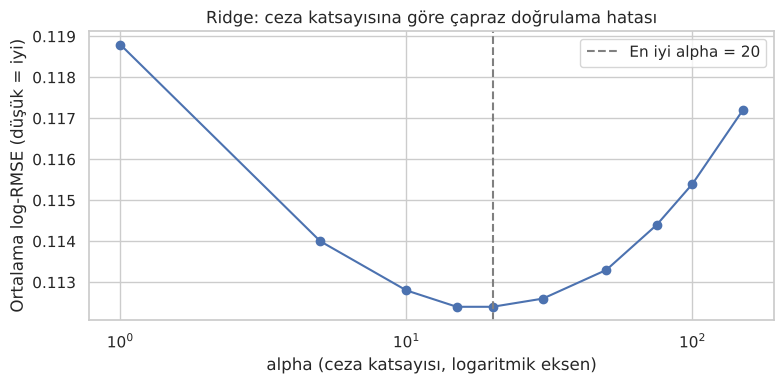

,alpha,Çapraz doğrulama log-RMSE
0,1,0.1188
1,5,0.1140
2,10,0.1128
3,15,0.1124
4,20,0.1124
5,30,0.1126
6,50,0.1133
7,75,0.1144
8,100,0.1154
9,150,0.1172


In [2]:
alpha_degerleri = [1, 5, 10, 15, 20, 30, 50, 75, 100, 150]
arama = GridSearchCV(
    hat_olustur(Ridge(), X_train),
    {"model__alpha": alpha_degerleri},
    cv=KATLAR, scoring="neg_root_mean_squared_error")
arama.fit(X_train, y_train)

alpha_tablo = pd.DataFrame({
    "alpha": alpha_degerleri,
    "Çapraz doğrulama log-RMSE": -arama.cv_results_["mean_test_score"],
}).round(4)
EN_IYI_ALPHA = arama.best_params_["model__alpha"]
print(f"En iyi alpha: {EN_IYI_ALPHA}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(alpha_tablo["alpha"], alpha_tablo["Çapraz doğrulama log-RMSE"], marker="o")
ax.axvline(EN_IYI_ALPHA, color="gray", linestyle="--", label=f"En iyi alpha = {EN_IYI_ALPHA}")
ax.set_xscale("log")
ax.set_xlabel("alpha (ceza katsayısı, logaritmik eksen)")
ax.set_ylabel("Ortalama log-RMSE (düşük = iyi)")
ax.set_title("Ridge: ceza katsayısına göre çapraz doğrulama hatası")
ax.legend()
plt.tight_layout()
plt.savefig("h7_ridge_alpha.png", dpi=300)
plt.show()
alpha_tablo

**Sonuç:** Eğri U şeklinde; hata alpha 15–20 civarında en düşük, daha büyük değerlerde yeniden artıyor.
Yani 20 artık aralığın ucunda değil, gerçekten en iyi bölgede. Ridge için **alpha = 20** kullanılacak.

## 2. Dört modelin karşılaştırılması ve eğitim süreleri (FR-07, FR-09, FR-10, NFR-04)
- **Linear Regression:** Gereksinim raporundaki (FR-07) cezasız doğrusal model.
- **Ridge:** Yukarıda bulunan en iyi alpha ile.
- **Random Forest:** 5. haftadaki ayarlar (100 ağaç).
- **Gradient Boosting:** 6. haftada bulunan en iyi ayarlar (250 ağaç, öğrenme hızı 0,05, derinlik 3).

Her model için: beş katlı çapraz doğrulama ortalaması (eğitim kümesinde), test kümesi sonuçları (dolar cinsinden) ve eğitim süresi.

In [3]:
modeller = {
    "Linear Regression": LinearRegression(),
    f"Ridge (alpha={EN_IYI_ALPHA})": Ridge(alpha=EN_IYI_ALPHA),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=250, learning_rate=0.05, max_depth=3, random_state=RANDOM_STATE),
}

y_test_dolar = np.expm1(y_test)
satirlar, egitilmis = [], {}
for ad, model in modeller.items():
    cv = cross_validate(hat_olustur(model, X_train), X_train, y_train, cv=KATLAR,
                        scoring=["r2", "neg_root_mean_squared_error"])

    hat = hat_olustur(model, X_train)
    baslangic = time.perf_counter()
    hat.fit(X_train, y_train)
    sure = time.perf_counter() - baslangic          # NFR-04: eğitim süresi
    egitilmis[ad] = hat

    tahmin = np.expm1(hat.predict(X_test))
    satirlar.append({
        "Model": ad,
        "CV R² (ort.)": cv["test_r2"].mean(),
        "CV R² (std)": cv["test_r2"].std(),
        "CV log-RMSE": -cv["test_neg_root_mean_squared_error"].mean(),
        "Test MAE ($)": mean_absolute_error(y_test_dolar, tahmin),
        "Test RMSE ($)": np.sqrt(mean_squared_error(y_test_dolar, tahmin)),
        "Test R²": r2_score(y_test_dolar, tahmin),
        "Eğitim süresi (sn)": sure,
    })

sonuclar = pd.DataFrame(satirlar).set_index("Model")
sonuclar.style.format({
    "CV R² (ort.)": "{:.4f}", "CV R² (std)": "±{:.4f}", "CV log-RMSE": "{:.4f}",
    "Test MAE ($)": "{:,.0f}", "Test RMSE ($)": "{:,.0f}", "Test R²": "{:.4f}",
    "Eğitim süresi (sn)": "{:.2f}"})

,CV R² (ort.),CV R² (std),CV log-RMSE,Test MAE ($),Test RMSE ($),Test R²,Eğitim süresi (sn)
Model,,,,,,,
Linear Regression,0.8899,±0.0268,0.1298,"14,931","21,056",0.9155,0.09
Ridge (alpha=20),0.9178,±0.0147,0.1124,"14,028","19,813",0.9252,0.06
Random Forest,0.8860,±0.0199,0.1326,"16,285","24,135",0.8890,0.77
Gradient Boosting,0.9056,±0.0203,0.1203,"13,947","20,483",0.9201,1.42


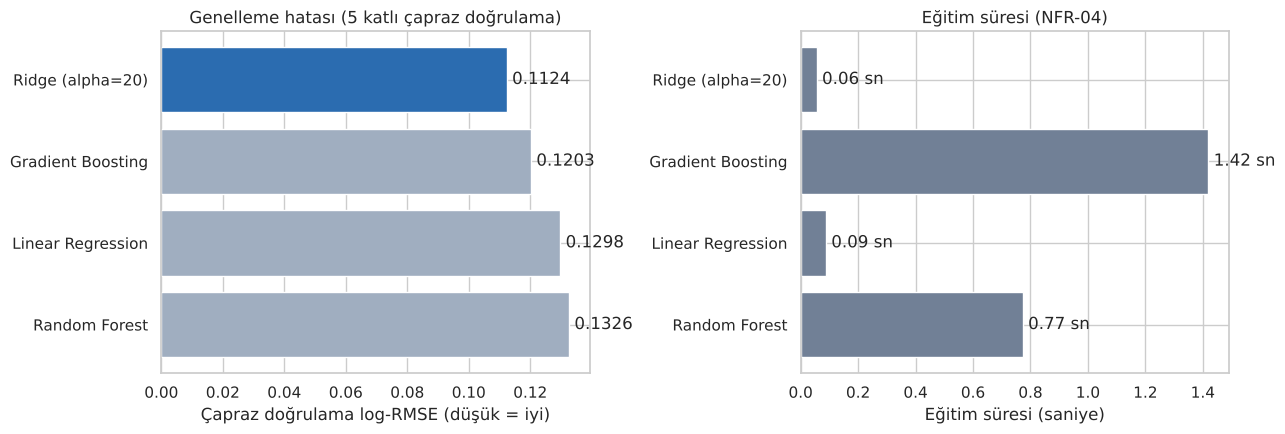

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sirali = sonuclar.sort_values("CV log-RMSE")
renkler = ["#2b6cb0" if i == 0 else "#a0aec0" for i in range(len(sirali))]

axes[0].barh(sirali.index[::-1], sirali["CV log-RMSE"][::-1], color=renkler[::-1],
             xerr=None)
axes[0].set_xlabel("Çapraz doğrulama log-RMSE (düşük = iyi)")
axes[0].set_title("Genelleme hatası (5 katlı çapraz doğrulama)")
for i, v in enumerate(sirali["CV log-RMSE"][::-1]):
    axes[0].text(v, i, f" {v:.4f}", va="center")

axes[1].barh(sirali.index[::-1], sirali["Eğitim süresi (sn)"][::-1], color="#718096")
axes[1].set_xlabel("Eğitim süresi (saniye)")
axes[1].set_title("Eğitim süresi (NFR-04)")
for i, v in enumerate(sirali["Eğitim süresi (sn)"][::-1]):
    axes[1].text(v, i, f" {v:.2f} sn", va="center")

plt.tight_layout()
plt.savefig("h7_model_karsilastirma.png", dpi=300)
plt.show()

## 3. Nihai modelin seçilmesi (FR-11)
**Seçim kuralı:** Eğitim kümesindeki beş katlı çapraz doğrulamada **en düşük ortalama log-RMSE** veren model seçilir.

Neden test sonucuna göre değil? Test kümesi tek bir 292 evlik örnektir; seçim ona göre yapılırsa
şanslı bir ayrıma göre karar verilmiş olur. Çapraz doğrulama beş farklı bölmenin ortalamasıdır, daha güvenilirdir.
Test kümesi yalnızca seçilen modelin son kontrolü için kullanılır.

In [5]:
NIHAI_AD = sonuclar["CV log-RMSE"].idxmin()
nihai = sonuclar.loc[NIHAI_AD]
ikinci = sonuclar.drop(NIHAI_AD).sort_values("CV log-RMSE").iloc[0]

print(f"Seçilen nihai model : {NIHAI_AD}")
print(f"  Çapraz doğrulama  : R² = {nihai['CV R² (ort.)']:.4f} (±{nihai['CV R² (std)']:.4f}), "
      f"log-RMSE = {nihai['CV log-RMSE']:.4f}")
print(f"  Test kümesi       : R² = {nihai['Test R²']:.4f}, MAE = {nihai['Test MAE ($)']:,.0f} $, "
      f"RMSE = {nihai['Test RMSE ($)']:,.0f} $")
print(f"  Eğitim süresi     : {nihai['Eğitim süresi (sn)']:.2f} saniye")
print(f"İkinci sıradaki model: {ikinci.name} (log-RMSE = {ikinci['CV log-RMSE']:.4f})")
print(f"Ortalama hata / ortalama fiyat: %{nihai['Test MAE ($)'] / y_test_dolar.mean() * 100:.1f}")

Seçilen nihai model : Ridge (alpha=20)
  Çapraz doğrulama  : R² = 0.9178 (±0.0147), log-RMSE = 0.1124
  Test kümesi       : R² = 0.9252, MAE = 14,028 $, RMSE = 19,813 $
  Eğitim süresi     : 0.06 saniye
İkinci sıradaki model: Gradient Boosting (log-RMSE = 0.1203)
Ortalama hata / ortalama fiyat: %8.0


### Seçimin gerekçesi
- **Ridge, çapraz doğrulamada en düşük hatayı veriyor** (log-RMSE 0,1124) ve **en kararlı model** (R² standart sapması ±0,0147, en düşük).
- **Testte Gradient Boosting'in ortalama mutlak hatası biraz daha düşük** (13.947 $'a karşı 14.028 $, yalnızca 81 $ fark).
  Ancak beş farklı bölmenin ortalamasında Ridge belirgin şekilde önde; tek bir test kümesindeki bu küçük fark şans eseri olabilir.
  Seçimi çapraz doğrulamaya göre yapmamızın sebebi tam olarak budur.
- **Ridge, Gradient Boosting'den onlarca kat daha hızlı eğitiliyor** (kesin süreler yukarıdaki tabloda; bilgisayara göre biraz değişir) ve doğrusal olduğu için kararları katsayılarla açıklanabiliyor.
- **Düz Linear Regression ile karşılaştırma (FR-07):** Cezasız doğrusal model çapraz doğrulamada belirgin şekilde geride
  (R² 0,8899 ±0,0268). 252 sütunun birbirine bağımlı olması katsayıları kararsızlaştırıyor; Ridge'in cezası bu sorunu çözüyor.
  Gereksinimdeki "Linear" modelin Ridge biçiminde kullanılmasının gerekçesi budur.

> Not: Random Forest ve Gradient Boosting sonuçları ve tüm eğitim süreleri bilgisayara ve kütüphane sürümüne göre çok az değişebilir.

## 4. Nihai model hangi özelliklere önem veriyor?
Ridge doğrusal bir model olduğu için her sütunun bir **katsayısı** vardır.
- Sayısal sütunlar ölçeklendiği için katsayılar birbiriyle karşılaştırılabilir.
- Hedef değişken log ölçeğinde olduğundan, katsayı yaklaşık olarak **o özellik bir standart sapma arttığında fiyatın yüzde kaç değiştiğini** gösterir
  (tam hesap: `(e^katsayı − 1) × 100`).
- Mahalle gibi one-hot sütunlarda katsayı, o kategoride olmanın fiyata etkisidir.

Pozitif katsayı fiyatı artırır, negatif katsayı düşürür.

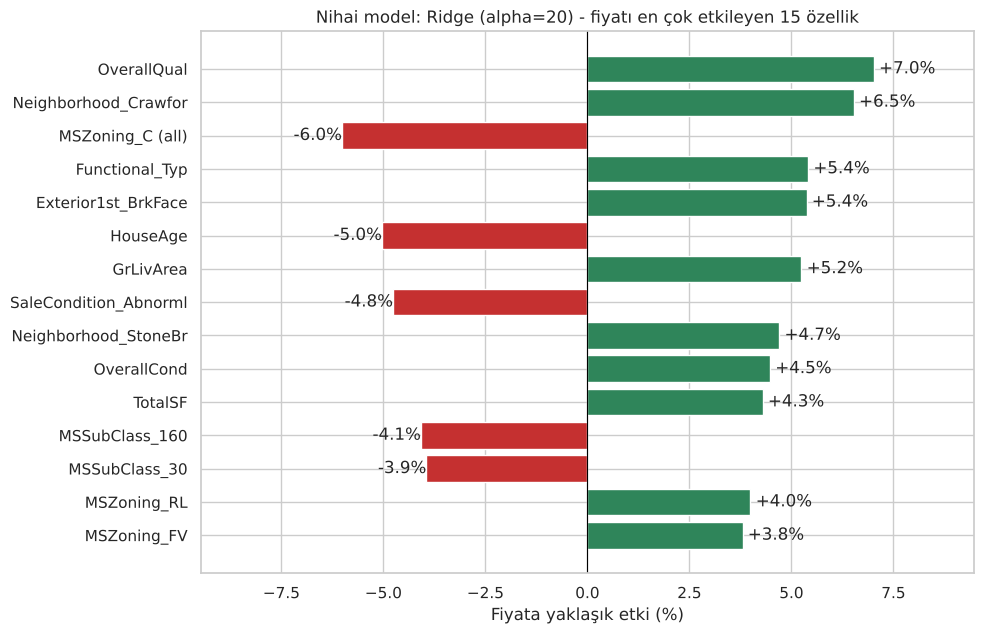

,Katsayı,Fiyata yaklaşık etki (%)
OverallQual,0.0678,7.0
Neighborhood_Crawfor,0.0632,6.5
MSZoning_C (all),-0.0620,-6.0
Functional_Typ,0.0527,5.4
Exterior1st_BrkFace,0.0523,5.4
HouseAge,-0.0517,-5.0
GrLivArea,0.0511,5.2
SaleCondition_Abnorml,-0.0488,-4.8
Neighborhood_StoneBr,0.0459,4.7
OverallCond,0.0438,4.5


In [6]:
nihai_hat = egitilmis[NIHAI_AD]
isimler = (pd.Series(nihai_hat.named_steps["on_isleme"].get_feature_names_out())
           .str.replace(r"^(numeric|ordinal|nominal|lotfrontage)__", "", regex=True))
katsayilar = pd.Series(nihai_hat.named_steps["model"].coef_, index=isimler)
ilk15 = katsayilar.reindex(katsayilar.abs().sort_values(ascending=False).index).head(15)
etki = (np.exp(ilk15) - 1) * 100

fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(etki.index[::-1], etki.values[::-1],
        color=["#2f855a" if v > 0 else "#c53030" for v in etki.values[::-1]])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Fiyata yaklaşık etki (%)")
ax.set_title(f"Nihai model: {NIHAI_AD} - fiyatı en çok etkileyen 15 özellik")
sinir = etki.abs().max() * 1.35
ax.set_xlim(-sinir, sinir)
for i, v in enumerate(etki.values[::-1]):
    ax.text(v, i, f" {v:+.1f}%", va="center", ha="left" if v > 0 else "right")
plt.tight_layout()
plt.savefig("h7_ridge_katsayilar.png", dpi=300)
plt.show()

pd.DataFrame({"Katsayı": ilk15.round(4), "Fiyata yaklaşık etki (%)": etki.round(1)})

**Yorum:**
- **Genel kalite (OverallQual) en etkili özellik:** 3. haftadaki keşifsel analizde fiyatla en yüksek korelasyona sahip olan özellik de buydu (r = 0,80).
- **Konum çok önemli:** Crawford ve Stone Brook mahalleleri fiyatı artırıyor. Ticari bölge imarı (`MSZoning_C`) ise fiyatı yaklaşık %6 düşürüyor.
- **Bina yaşı (HouseAge) fiyatı düşürüyor**, genel durum (OverallCond) ise artırıyor.
- **Alan özellikleri:** Yaşam alanı (GrLivArea) ve toplam alan (TotalSF) birbirine çok bağlı olduğu için Ridge etkiyi ikisine paylaştırıyor.
  Bu yüzden ikisi ayrı ayrı orta sırada görünüyor; birlikte düşünüldüğünde alan, kaliteyle birlikte en güçlü etkendir.
- **Olağandışı satış (SaleCondition_Abnorml)** fiyatı yaklaşık %5 düşürüyor.

> 6. haftadaki özellik önem grafiği Gradient Boosting modelinden alınmıştı. Bu grafik ise nihai model olan Ridge'e aittir.

## 5. Hata analizi
Model nerede ve ne kadar yanılıyor? Üç açıdan bakıyoruz:
1. **Gerçek ve tahmin edilen fiyat:** Noktalar kırmızı köşegene ne kadar yakınsa tahmin o kadar iyidir.
2. **Fiyat aralığına göre hata:** Model ucuz ve pahalı evlerde aynı başarıda mı?
3. **En çok yanılınan 10 ev:** Bu evlerin ortak bir özelliği var mı?

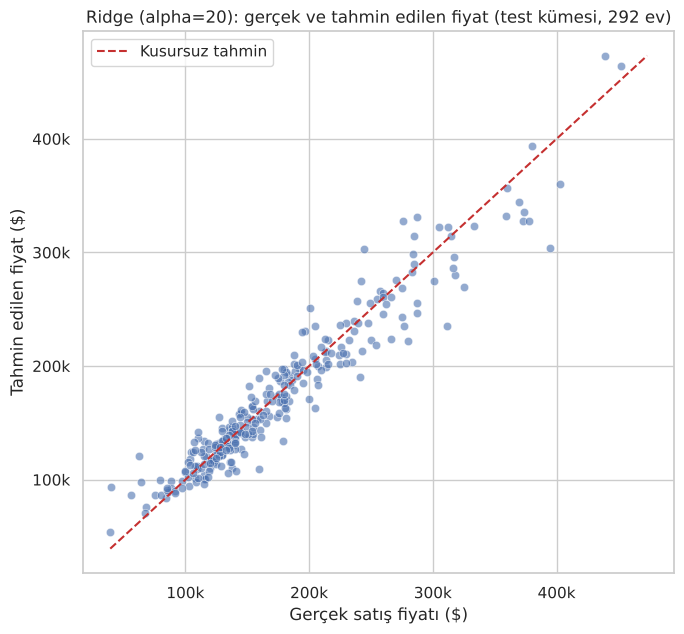

Tahminlerin %71'i gerçek fiyata %10'dan daha yakın.


In [7]:
tahmin_dolar = np.expm1(nihai_hat.predict(X_test))
analiz = X_test[["Id", "Neighborhood", "OverallQual", "GrLivArea", "YearBuilt", "SaleCondition"]].copy()
analiz["Gerçek fiyat"] = y_test_dolar.values
analiz["Tahmin"] = tahmin_dolar
analiz["Hata ($)"] = analiz["Tahmin"] - analiz["Gerçek fiyat"]
analiz["Mutlak hata (%)"] = (analiz["Hata ($)"].abs() / analiz["Gerçek fiyat"] * 100)

fig, ax = plt.subplots(figsize=(7, 6.5))
ax.scatter(analiz["Gerçek fiyat"], analiz["Tahmin"], alpha=0.6, edgecolor="white", linewidth=0.5)
sinir = [analiz[["Gerçek fiyat", "Tahmin"]].min().min(), analiz[["Gerçek fiyat", "Tahmin"]].max().max()]
ax.plot(sinir, sinir, color="#c53030", linestyle="--", label="Kusursuz tahmin")
ax.set_xlabel("Gerçek satış fiyatı ($)")
ax.set_ylabel("Tahmin edilen fiyat ($)")
ax.set_title(f"{NIHAI_AD}: gerçek ve tahmin edilen fiyat (test kümesi, 292 ev)")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
ax.legend()
plt.tight_layout()
plt.savefig("h7_gercek_tahmin.png", dpi=300)
plt.show()

print(f"Tahminlerin %{(analiz['Mutlak hata (%)'] <= 10).mean() * 100:.0f}'i gerçek fiyata %10'dan daha yakın.")

In [8]:
araliklar = [0, 100_000, 200_000, 300_000, np.inf]
etiketler = ["100 bin $ altı", "100–200 bin $", "200–300 bin $", "300 bin $ üstü"]
analiz["Fiyat aralığı"] = pd.cut(analiz["Gerçek fiyat"], araliklar, labels=etiketler)

aralik_tablo = analiz.groupby("Fiyat aralığı", observed=True).agg(
    **{"Ev sayısı": ("Gerçek fiyat", "size"),
       "Ortalama mutlak hata ($)": ("Hata ($)", lambda h: h.abs().mean()),
       "Ortalama mutlak hata (%)": ("Mutlak hata (%)", "mean"),
       "Ortalama yön ($)": ("Hata ($)", "mean")})
aralik_tablo.style.format({"Ortalama mutlak hata ($)": "{:,.0f}", "Ortalama mutlak hata (%)": "{:.1f}",
                           "Ortalama yön ($)": "{:+,.0f}"})

,Ev sayısı,Ortalama mutlak hata ($),Ortalama mutlak hata (%),Ortalama yön ($)
Fiyat aralığı,,,,
100 bin $ altı,20,"14,134",24.2,"+13,115"
100–200 bin $,189,"10,487",7.3,-96
200–300 bin $,62,"18,723",7.7,"-5,155"
300 bin $ üstü,21,"31,937",9.0,"-23,435"


**"Ortalama yön" sütunu nasıl okunur?** Pozitifse model o aralıkta fiyatı genelde **olduğundan yüksek**,
negatifse **olduğundan düşük** tahmin ediyor demektir.

In [9]:
en_kotu = analiz.reindex(analiz["Hata ($)"].abs().sort_values(ascending=False).index).head(10)
en_kotu.style.format({"Gerçek fiyat": "{:,.0f}", "Tahmin": "{:,.0f}",
                      "Hata ($)": "{:+,.0f}", "Mutlak hata (%)": "{:.1f}"})

,Id,Neighborhood,OverallQual,GrLivArea,YearBuilt,SaleCondition,Gerçek fiyat,Tahmin,Hata ($),Mutlak hata (%),Fiyat aralığı
772,775,NridgHt,8,1973,2006,Partial,"395,000","303,965","-91,035",23.0,300 bin $ üstü
218,219,Crawfor,7,1954,1939,Normal,"311,500","234,873","-76,627",24.6,300 bin $ üstü
70,71,NAmes,7,2223,1973,Normal,"244,000","303,308","+59,308",24.3,200–300 bin $
462,463,Sawyer,5,864,1965,Normal,"62,383","120,848","+58,465",93.7,100 bin $ altı
451,452,ClearCr,7,1533,1975,Normal,"280,000","222,495","-57,505",20.5,200–300 bin $
582,584,OldTown,10,2775,1893,Normal,"325,000","269,500","-55,500",17.1,300 bin $ üstü
30,31,IDOTRR,4,1317,1920,Normal,"40,000","93,505","+53,505",133.8,100 bin $ altı
261,262,CollgCr,8,2574,2007,Partial,"276,000","327,526","+51,526",18.7,200–300 bin $
271,272,ClearCr,7,1363,1954,Normal,"241,500","190,135","-51,365",21.3,200–300 bin $
680,682,SWISU,5,1520,1932,Abnorml,"159,434","109,385","-50,049",31.4,100–200 bin $


In [10]:
print("En çok yanılınan 10 evin satış koşulu (SaleCondition):")
print(en_kotu["SaleCondition"].value_counts().to_string())
print()
print("Test kümesinin tamamında satış koşulu oranları:")
print((analiz["SaleCondition"].value_counts(normalize=True) * 100).round(1).astype(str).add(" %").to_string())

En çok yanılınan 10 evin satış koşulu (SaleCondition):
SaleCondition
Normal     7
Partial    2
Abnorml    1

Test kümesinin tamamında satış koşulu oranları:
SaleCondition
Normal     81.5 %
Abnorml     8.6 %
Partial     7.9 %
Alloca      1.7 %
Family      0.3 %


**SaleCondition (satış koşulu) nedir?** `Normal` sıradan satış, `Abnorml` olağandışı satış (haciz, zorunlu satış vb.),
`Partial` henüz tamamlanmamış yeni ev satışı, `Family` aile içi satıştır.

### Hata analizinin sonuçları
- **En büyük hatalar satış koşulundan kaynaklanmıyor:** En çok yanılınan 10 evin 7'si normal satış; olağandışı satış oranı
  (%10) test kümesinin genelindeki orana (%8,6) yakın.
- **Asıl desen fiyatın uç değerlerinde:** Model ucuz evleri olduğundan **pahalı** (100 bin $ altında ortalama +13 bin $),
  pahalı evleri olduğundan **ucuz** (300 bin $ üstünde ortalama −23 bin $) tahmin ediyor. Buna **ortalamaya çekilme** denir:
  veri setinde az sayıda çok ucuz ve çok pahalı ev olduğu için model tahminlerini ortalamaya doğru çeker.
- **Orta segmentte model çok başarılı:** Evlerin %65'inin bulunduğu 100–200 bin $ aralığında ortalama hata %7,3 ve yönsüz (−96 $).
- **Yüzde olarak en zor grup çok ucuz evler:** 100 bin $ altında ortalama hata %24. Örneğin 40.000 $'a satılan 1920 yapımı,
  kalitesi düşük (4) bir ev 93.505 $ tahmin edilmiş; bu evlerde fiyatı evin genel özelliklerinin açıklayamadığı başka etkenler belirliyor olabilir.

## 6. Nihai modelin kaydedilmesi
Kaydedilecek nihai model için iki karar:
1. **Tüm veriyle yeniden eğitim:** Değerlendirme bitti; artık modelin olabildiğince çok evden öğrenmesi istenir.
   Bu yüzden nihai model 1.456 evin tamamıyla yeniden eğitilir. (Yukarıdaki test sonuçları, test kümesini hiç görmemiş modele aittir.)
2. **Fiyatı doğrudan dolar olarak vermesi:** `TransformedTargetRegressor`, eğitimde log dönüşümünü uygular,
   tahminde ise sonucu otomatik olarak dolara çevirir. Temizlik ve özellik türetme adımları da modelin içindedir;
   böylece model ham ev bilgisini doğrudan kabul eder ve sonraki haftalarda başka bir programdan kolayca kullanılabilir.

In [11]:
nihai_model = TransformedTargetRegressor(
    regressor=hat_olustur(Ridge(alpha=EN_IYI_ALPHA), X),
    func=np.log1p, inverse_func=np.expm1)
nihai_model.fit(X, df["SalePrice"])
joblib.dump(nihai_model, "nihai_model.pkl")
print("Kaydedildi: nihai_model.pkl")

Kaydedildi: nihai_model.pkl


### Kaydedilen modelin testi
Model dosyadan yeniden yüklenir. Dosyadan yüklenen modelin, bellekteki modelle **birebir aynı** tahminleri ürettiği kontrol edilir
ve birkaç örnek ev için tahmin gösterilir. Bu test modelin başarısını değil, **dosyanın doğru kaydedildiğini** doğrular
(başarı yukarıda test kümesiyle ölçülmüştü).

In [12]:
yuklenen = joblib.load("nihai_model.pkl")
ayni_mi = np.allclose(yuklenen.predict(X_test), nihai_model.predict(X_test))
print(f"Dosyadan yüklenen model bellekteki modelle aynı tahminleri veriyor mu? {'Evet' if ayni_mi else 'Hayır'}")

ornekler = X_test.head(5)
pd.DataFrame({
    "Id": ornekler["Id"].values,
    "Mahalle": ornekler["Neighborhood"].values,
    "Genel kalite": ornekler["OverallQual"].values,
    "Gerçek fiyat ($)": np.expm1(y_test.head(5)).round().astype(int).values,
    "Kaydedilen modelin tahmini ($)": yuklenen.predict(ornekler).round().astype(int),
}).style.format({"Gerçek fiyat ($)": "{:,}", "Kaydedilen modelin tahmini ($)": "{:,}"})

Dosyadan yüklenen model bellekteki modelle aynı tahminleri veriyor mu? Evet


,Id,Mahalle,Genel kalite,Gerçek fiyat ($),Kaydedilen modelin tahmini ($)
0,498,BrkSide,7,"184,000","168,393"
1,1265,NAmes,6,"181,000","159,128"
2,412,Gilbert,5,"145,000","130,897"
3,1049,Mitchel,5,"115,000","128,809"
4,1036,Edwards,4,"84,000","80,667"
